In [60]:
import time
import numpy as np
import pandas as pd

from sklearn.datasets import fetch_california_housing, load_diabetes, fetch_openml
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_SEED = 42
N_SPLITS = 5


In [61]:
def load_california_ds():
    data = fetch_california_housing()
    return data.data, data.target

def load_diabetes_ds():
    data = load_diabetes()
    return data.data, data.target

def load_concrete_ds():
    data = fetch_openml(data_id=4353, as_frame=False, parser="liac-arff")
    X = data.data[:, :-1].astype(float)
    y = data.data[:, -1].astype(float)
    return X, y


datasets = {
    "California": load_california_ds(),
    "Diabetes": load_diabetes_ds(),
    "Concrete": load_concrete_ds()
}


In [62]:
def get_models(random_seed):
    return {
        "LinearRegression": LinearRegression(),
        "RandomForest": RandomForestRegressor(
            n_estimators=100,
            random_state=random_seed,
            n_jobs=-1
        ),
        "MLP": MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            max_iter=1000,
            early_stopping=True,
            random_state=random_seed
        )
    }


In [63]:
results = []

for dataset_name, (X, y) in datasets.items():
    
    print(f"\nDataset: {dataset_name}")
    print("Shape:", X.shape, y.shape)
    
    kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    
    dataset_results = []
    
    for model_name in get_models(RANDOM_SEED).keys():
        fold_metrics = []
        
        for train_idx, test_idx in kf.split(X):
            
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]
            
            # scale inside fold (correct way)
            scaler = StandardScaler()
            if model_name in ["LinearRegression", "MLP"]:
                X_train = scaler.fit_transform(X_train)
                X_test = scaler.transform(X_test)
            
            model = get_models(RANDOM_SEED)[model_name]
            
            start_train = time.time()
            model.fit(X_train, y_train)
            train_time = time.time() - start_train
            
            start_inf = time.time()
            y_pred = model.predict(X_test)
            inf_time = time.time() - start_inf
            
            mse = mean_squared_error(y_test, y_pred)
            mae = mean_absolute_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)
            
            fold_metrics.append([mse, mae, r2, train_time, inf_time])
        
        fold_metrics = np.array(fold_metrics)
        
        dataset_results.append([
            model_name,
            fold_metrics[:,0].mean(),
            fold_metrics[:,1].mean(),
            fold_metrics[:,2].mean(),
            fold_metrics[:,3].mean(),
            fold_metrics[:,4].mean()
        ])
    
    df = pd.DataFrame(
        dataset_results,
        columns=["Model", "MSE", "MAE", "R2", "Train_time", "Inference_time"]
    )
    
    print(df.sort_values("MSE"))
    
    results.append((dataset_name, df))



Dataset: California
Shape: (20640, 8) (20640,)
              Model       MSE       MAE        R2  Train_time  Inference_time
1      RandomForest  0.253467  0.327779  0.809571    0.851128        0.040024
2               MLP  0.282458  0.361626  0.787859    3.367207        0.001726
0  LinearRegression  0.530572  0.531677  0.601378    0.002788        0.000172

Dataset: Diabetes
Shape: (442, 10) (442,)
              Model          MSE        MAE        R2  Train_time  \
0  LinearRegression  3015.381694  44.269746  0.478470    0.000491   
1      RandomForest  3314.627391  46.692527  0.429359    0.122013   
2               MLP  3860.421265  48.364726  0.344136    0.402205   

   Inference_time  
0        0.000072  
1        0.029754  
2        0.000143  

Dataset: Concrete
Shape: (1030, 8) (1030,)
              Model         MSE       MAE        R2  Train_time  \
1      RandomForest   26.246926  3.509188  0.905774    0.137477   
2               MLP   35.951675  4.448008  0.871253    1.24239

In [69]:
plot_rows = []

for dataset_name, df in results:
    for _, row in df.iterrows():
        plot_rows.append([
            dataset_name,
            row["Model"],
            row["Train_time"],
            row["Inference_time"],
            row["MSE"],
            row["MAE"],
            row["R2"]
        ])

plot_df = pd.DataFrame(
    plot_rows,
    columns=["Dataset", "Model", "Train_time", "Inference_time", "MSE", "MAE", "R2"]
)

plot_df.head()


,Dataset,Model,Train_time,Inference_time,MSE,MAE,R2
0,California,LinearRegression,0.002788,0.000172,0.530572,0.531677,0.601378
1,California,RandomForest,0.851128,0.040024,0.253467,0.327779,0.809571
2,California,MLP,3.367207,0.001726,0.282458,0.361626,0.787859
3,Diabetes,LinearRegression,0.000491,0.000072,3015.381694,44.269746,0.478470
4,Diabetes,RandomForest,0.122013,0.029754,3314.627391,46.692527,0.429359


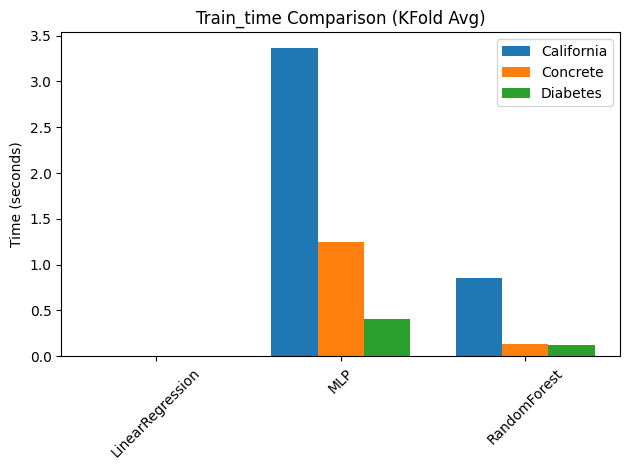

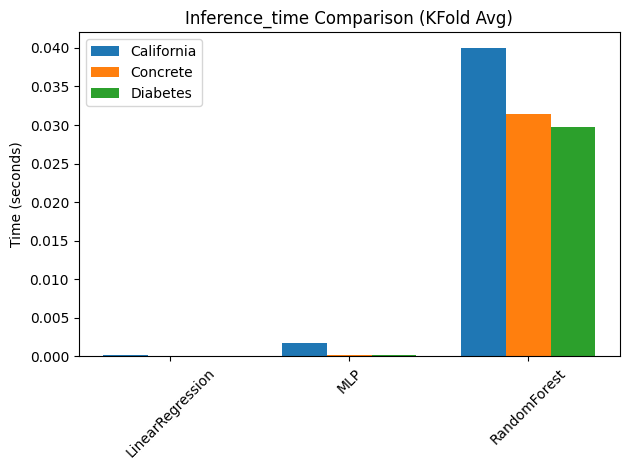

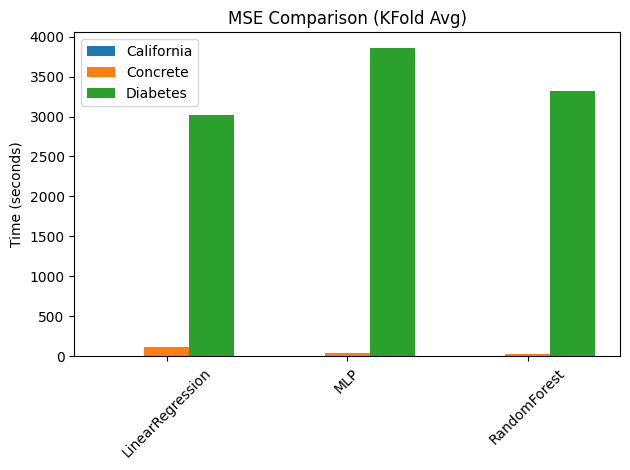

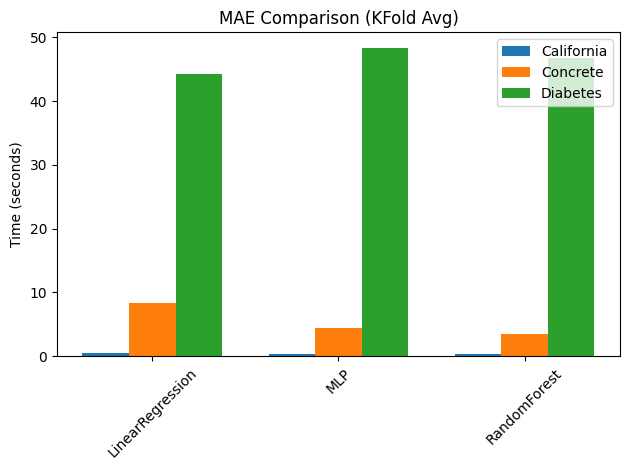

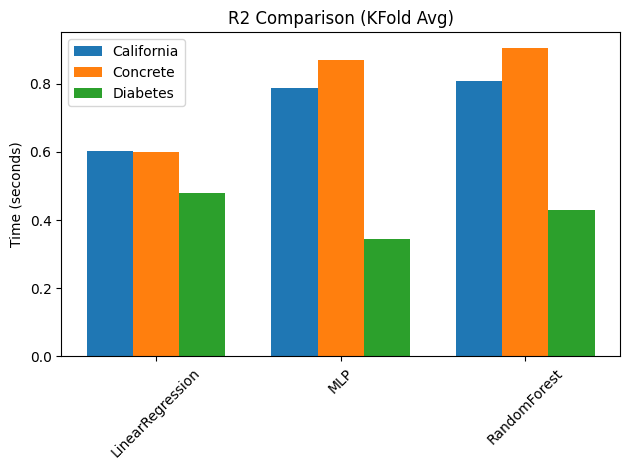

In [70]:
import numpy as np
import matplotlib.pyplot as plt

models = sorted(plot_df["Model"].unique())
datasets_unique = sorted(plot_df["Dataset"].unique())

x = np.arange(len(models))
width = 0.25

for metric in ["Train_time", "Inference_time", "MSE", "MAE", "R2"]:
    
    plt.figure()
    
    for i, dataset in enumerate(datasets_unique):
        subset = (
            plot_df[plot_df["Dataset"] == dataset]
            .set_index("Model")
            .loc[models]
        )
        
        plt.bar(
            x + i * width,
            subset[metric].values,
            width,
            label=dataset
        )
    
    plt.xticks(x + width, models, rotation=45)
    plt.ylabel("Time (seconds)")
    plt.title(f"{metric} Comparison (KFold Avg)")
    plt.legend()
    plt.tight_layout()
    plt.show()
